## Trabajo pratico integrador 
## Estadistica y Exploración de Datos II
### Alumna: Sol Josefina Mercado | 38.442.698


### Temática: Analisis sobre la actividad física y la quema de calorias, como dueña de gimnasio y entrenadora este analisis puede ser de utilidad para mis clientes.

#### Preguntas para EDA: 
* ¿Qué hace que un entrenamiento queme más calorías? 
* ¿Qué factores explican cuántas calorías quema una persona en una sesión de gimnasio? 
* ¿Importa más el tipo de entrenamiento o cómo se entrena (duración e intensidad)?

In [210]:
# carga del dataset
'''
El dataset: Gym Members Exercise Dataset (Vala Khorasani, Kaggle, 2024): 
kaggle.com/datasets/valakhorasani/gym-members-exercise-dataset. 
Tiene 973 filas y 15 columnas, y cada fila es un socio y su sesión de entrenamiento.
'''
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np

df = pd.read_csv("data/gym_members_exercise_tracking.csv")

In [211]:
df.info()

# No se registran valores faltantes en el dataset
# Variables CUALITATIVAS: Gender, Workout_Type, Experience_Level (ordinal 1-3). 
# Variables CUANTITATIVAS: Calories_Burned, Weight (kg), Height (m), Age, Session_Duration (hours), 
# Fat_Percentage, Avg_BPM, Max_BPM, Resting_BPM, Water_Intake (liters), BMI

<class 'pandas.DataFrame'>
RangeIndex: 973 entries, 0 to 972
Data columns (total 15 columns):
 #   Column                         Non-Null Count  Dtype  
---  ------                         --------------  -----  
 0   Age                            973 non-null    int64  
 1   Gender                         973 non-null    str    
 2   Weight (kg)                    973 non-null    float64
 3   Height (m)                     973 non-null    float64
 4   Max_BPM                        973 non-null    int64  
 5   Avg_BPM                        973 non-null    int64  
 6   Resting_BPM                    973 non-null    int64  
 7   Session_Duration (hours)       973 non-null    float64
 8   Calories_Burned                973 non-null    float64
 9   Workout_Type                   973 non-null    str    
 10  Fat_Percentage                 973 non-null    float64
 11  Water_Intake (liters)          973 non-null    float64
 12  Workout_Frequency (days/week)  973 non-null    int64  
 13  E

## Población, muestra y muestreo
* Poblacion: Todos los 973 registros (socios) del dataset.

* Muestra: Genero una muestra aleatoria estratificada según el nivel de experiencia (Experience_Level), en lugar de estratificar por género como en la versión anterior. La decisión se basa en el análisis exploratorio, que muestra mayores diferencias de gasto calórico entre niveles de experiencia que entre géneros. Desde el conocimiento del dominio, esto es esperable: el efecto del entrenamiento varía según el nivel de cada persona, porque influyen el dominio de la técnica, la carga utilizada y, posiblemente, la composición corporal (por ejemplo, el porcentaje de masa muscular). Al estratificar por esta variable, cada estrato agrupa individuos con un comportamiento más homogéneo, lo que mejora la precisión de las estimaciones.

* Unidad de análisis: Una persona en una sesion (un registro).

## Representatividad y tipo de muestreo

### El dataset original no es una muestra probabilística.
Una muestra es probabilística cuando:

* Se conoce la probabilidad de cada elemento de la población de ser incluido en la muestra.
* La selección se realiza mediante un procedimiento aleatorio.
* Las estimaciones tienen en cuenta esas probabilidades.

El dataset de Kaggle no documenta cómo se seleccionaron los 973 registros. Al no poder verificar ninguna de estas condiciones, se lo considera una muestra no probabilística, y por lo tanto no es posible generalizar sus resultados a todos los socios de gimnasios.

* Decisión metodológica: tomo los 973 registros como población de estudio (N = 973) y, a partir de ella, extraigo una muestra probabilística estratificada por nivel de experiencia (`Experience_Level`).

* Alcance: las conclusiones de este trabajo son válidas para estos 973 socios.

In [212]:
# Parámetros (población = dataset completo)
promedio_poblacional = df["Calories_Burned"].mean()

# Muestra estratificada proporcional por nivel de experiencia (30%)
muestra = df.groupby("Experience_Level").sample(frac=0.30, random_state=42)

# Estadístico
promedio_muestral = muestra["Calories_Burned"].mean()
print('promedio de gasto calórico\nPoblacion - Muestra')
print(f'{promedio_poblacional.round(2)}  -  {promedio_muestral.round(2)}')
print()

err = promedio_muestral - promedio_poblacional
print(f'Error: {err.round(2)} calorías') 

promedio de gasto calórico
Poblacion - Muestra
905.42  -  916.62

Error: 11.2 calorías


## Parámetros y estadísticos (Calories_Burned) - EDA

La variable de interés es Calories_Burned, porque las tres preguntas de investigación:

* ¿Qué hace que un entrenamiento queme más calorías? 
* ¿Qué factores explican cuántas calorías quema una persona en una sesión de gimnasio? 
* ¿Importa más el tipo de entrenamiento o cómo se entrena (duración e intensidad)?

buscan explicar el gasto calórico por sesión. 
El parámetro central es su media poblacional, que estimo con la media muestral. A partir de ahí, comparo medias por nivel, y mido la relación con la duración y la intensidad mediante correlaciones y regresión.



## Cómo esta compuesta la muestra, en cuanto a la variable seleccionada para estratificar?
#### 1: Beginner 2: Intermediate 3: Expert
Las proporciones de cada nivel en la muestra con respecto a la poblacion se respetó, solo varia en .1 puntos porcentuales.
El grupo que predomina en la muestra es el 2 (Intermediate) y el que menos registros tiene es el 3 (Expert). Esto es un reflejo de la realidad.

In [213]:
comparacion = pd.DataFrame({
    'Cantidad Poblacion': df['Experience_Level'].value_counts(),
    'Cantidad Muestra': muestra['Experience_Level'].value_counts(),
    'Población (%)': (df['Experience_Level'].value_counts(normalize=True) * 100).round(1),
    'Muestra (%)': (muestra['Experience_Level'].value_counts(normalize=True) * 100).round(1)
}).sort_index()

display(comparacion)

,Cantidad Poblacion,Cantidad Muestra,Población (%),Muestra (%)
Experience_Level,,,,
1,376,113,38.6,38.7
2,406,122,41.7,41.8
3,191,57,19.6,19.5


In [214]:
muestra.describe()

,Age,Weight (kg),Height (m),Max_BPM,Avg_BPM,Resting_BPM,Session_Duration (hours),Calories_Burned,Fat_Percentage,Water_Intake (liters),Workout_Frequency (days/week),Experience_Level,BMI
count,292.000000,292.000000,292.000000,292.000000,292.000000,292.000000,292.000000,292.000000,292.000000,292.000000,292.000000,292.000000,292.000000
mean,38.113014,74.914726,1.717808,178.993151,144.380137,62.397260,1.261815,916.619863,25.272603,2.644178,3.318493,1.808219,25.400205
std,11.952263,21.123808,0.120009,11.584737,14.467977,7.382974,0.340868,273.259596,6.254544,0.593435,0.910761,0.739788,6.696506
min,18.000000,40.000000,1.500000,160.000000,120.000000,50.000000,0.510000,330.000000,10.100000,1.500000,2.000000,1.000000,12.320000
25%,28.000000,59.275000,1.620000,169.000000,131.750000,56.750000,1.040000,723.750000,21.375000,2.200000,3.000000,1.000000,20.985000
50%,37.500000,71.550000,1.710000,178.500000,143.000000,62.000000,1.280000,915.500000,26.550000,2.700000,3.000000,2.000000,25.080000
75%,49.000000,87.300000,1.790000,188.000000,157.250000,69.000000,1.452500,1105.250000,29.400000,3.200000,4.000000,2.000000,29.247500
max,59.000000,128.400000,2.000000,199.000000,169.000000,74.000000,2.000000,1766.000000,35.000000,3.700000,5.000000,3.000000,46.980000


## Cómo se distribuye el nivel de gasto calórico por nivel de experiencia?

Tenemos calculado que la media poblacional de gasto calórico es 905.42 kcal y la muestral 916.62 kcal por sesión (registro), pero este valor no distingue el efecto de las variables: de nivel de experiencia, tipo de entrenamiento, duración, o ritmo cardiaco promedio. 

Lo que haré para comprobar el efecto de distintos factores sobre el gasto calorico, es medir como varía la cantidad de calorias quemadas promedio con cada segmentacion, dentro de la muestra,y lo comparo con el valor promedio muestral para medir el impacto.

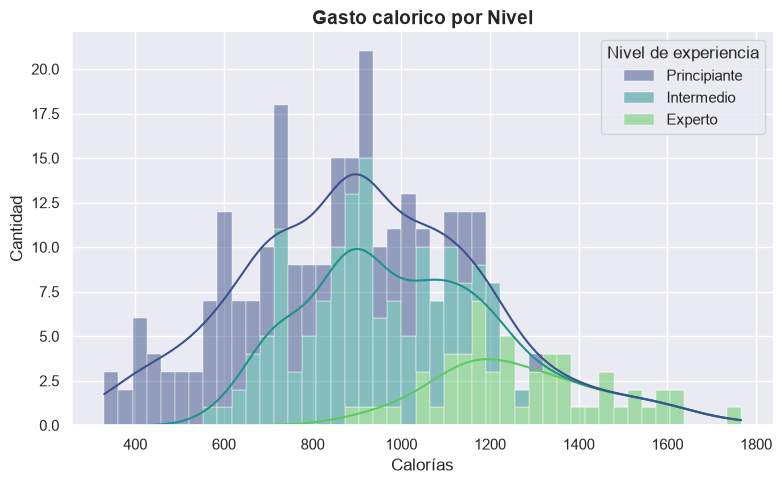

In [215]:
niveles = {'1': 'Principiante', '2': 'Intermedio', '3': 'Experto'}
muestra['Nivel'] = muestra['Experience_Level'].astype(str).map(niveles)

sns.set_theme(style='darkgrid')
fig, ax = plt.subplots(figsize=(8, 5))
sns.histplot(data=muestra, x='Calories_Burned', hue='Nivel',
             hue_order=['Principiante', 'Intermedio', 'Experto'],
             bins=45, log_scale=False, stat='count',
             multiple='stack', element='bars', kde=True,
             palette='viridis', edgecolor='white', linewidth=0.3, ax=ax)

ax.set_title('Gasto calorico por Nivel', fontsize=14, fontweight='bold')
ax.set_xlabel('Calorías')
ax.set_ylabel('Cantidad')
ax.get_legend().set_title('Nivel de experiencia')
sns.despine()
plt.tight_layout()
plt.show()

Se observa que el nivel de entrenamiento provoca una diferencia marcada de gasto calórico por sesión, con una diferencia de *-175 calorias en principiantes contra la media muestral*, *-5 puntos para intermedios* (podríamos decir que el gasto promedio corresponde a un nivel promedio, porque es el grupo mas grande también)
Y una diferencia de *+357 calorías por sesion en expertos*.

### Tabla Gasto calórico promedio por género

La diferencia en gasto calórico promedio, entre homrbes y mujeres es de 83 calorías.

### Tabla Gasto por nivel y género:

Si bien género aporta informacion, pensando en el modelo, Nivel es la variable que produce mayores variaciones en el promedio de gasto calórico. 

In [231]:
gasto_nivel = muestra.groupby('Experience_Level')['Calories_Burned'].mean().round(2)
gasto_genero = muestra.groupby('Gender')['Calories_Burned'].mean().round(2)
gasto_genero_nivel = muestra.groupby(['Gender','Experience_Level'])['Calories_Burned'].mean().round(2)
print('Gasto calórico promedio de la muestra', promedio_muestral.round(2))
print()
print('Gasto calórico promedio por nivel de experiencia\n',gasto_nivel)
print()
print('Gasto calórico promedio por género\n',gasto_genero)
print()
print('Gasto por nivel y género\n',gasto_genero_nivel) 

Gasto calórico promedio de la muestra 916.62

Gasto calórico promedio por nivel de experiencia
 Experience_Level
1     741.43
2     911.94
3    1273.93
Name: Calories_Burned, dtype: float64

Gasto calórico promedio por género
 Gender
Female    872.47
Male      955.65
Name: Calories_Burned, dtype: float64

Gasto por nivel y género
 Gender  Experience_Level
Female  1                    715.58
        2                    840.76
        3                   1219.31
Male    1                    764.27
        2                    970.37
        3                   1330.50
Name: Calories_Burned, dtype: float64


## Qué factor tiene un efecto mas alto sobre el gasto, el tipo de ejercicio o el nivel de experiencia?

A partir de la grafica podemos inferir:

* El nivel de entrenamiento tiene mayor importancia que el tipo de ejercicio para determinar el gasto calórico. 
Se comprueba que HIIT (Entrenamiento por intervalos) es la actividad que mas cantidad de calorías consume con una media de 1350 kcal en el nivel Experto, seguido por el entrenamiento de fuerza con una media aproximada de 1250 kcal en Experto. Esto se explica porque con un mayor dominio de las técnicas, mayor esfuerzo se puede realizar, y con mayores cargas, lo que aumenta el gasto.

* Cardio tiene una media similar en gasto que Strength, pero el rango intercuartilico es menor, esto por la naturaleza de la actividad, cuyas adaptaciones generan un aumento de la eficiencia del movimiento y de utilizacion de la energía. 
Ademas es el unico estrato que presenta outliers.

* Para los niveles Intermedio los niveles de media de gasto calorico están mas parejos entre tipos de ejercicio, tambien sus minimos y máximos.

* El estrato que presenta mayor variacion de gasto son los principiantes, con la media de gasto mas elevada, y máximo de gasto para Stength.

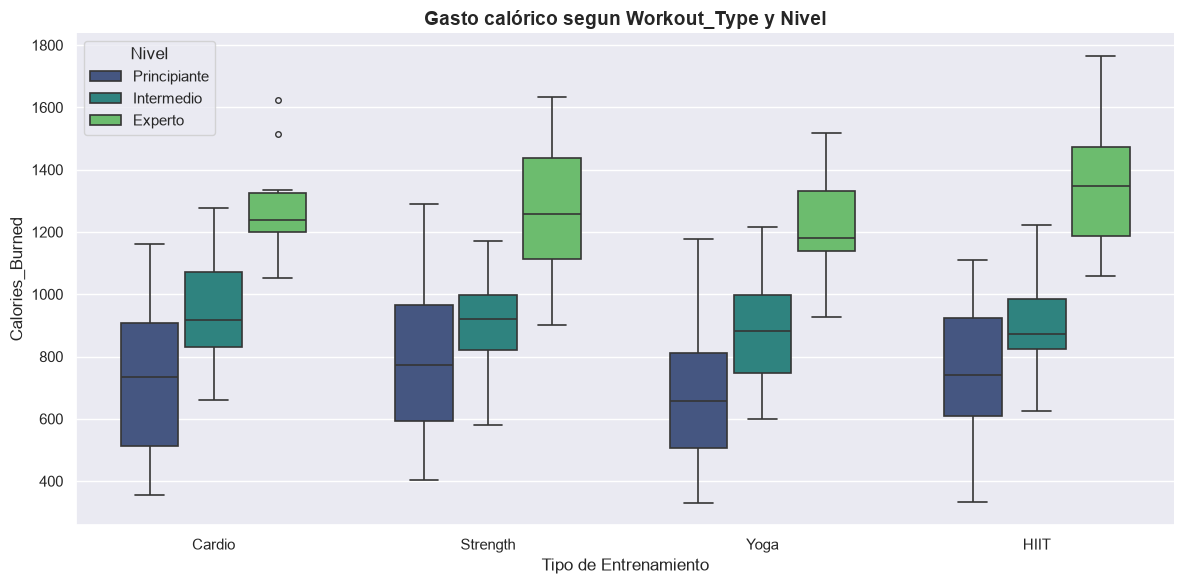

In [217]:
sns.set_theme(style='darkgrid')
fig, ax = plt.subplots(figsize=(12, 6))
sns.boxplot(data=muestra, y='Calories_Burned', x='Workout_Type', hue='Nivel',
            hue_order=['Principiante', 'Intermedio', 'Experto'],
            palette='viridis', width=0.7, gap=0.1, whis=1.5,
            fliersize=4, linewidth=1.2, ax=ax)

ax.set_title('Gasto calórico segun Workout_Type y Nivel', fontsize=14, fontweight='bold')
ax.set_xlabel('Tipo de Entrenamiento')
sns.despine()

plt.tight_layout()
plt.show()


### Outliers: Cardio Experto

In [218]:
outliers = muestra.loc[
    (muestra['Workout_Type'] == 'Cardio') &
    (muestra['Calories_Burned'] > 1500)
]
outliers

,Age,Gender,Weight (kg),Height (m),Max_BPM,Avg_BPM,Resting_BPM,Session_Duration (hours),Calories_Burned,Workout_Type,Fat_Percentage,Water_Intake (liters),Workout_Frequency (days/week),Experience_Level,BMI,Nivel
99,24,Female,60.1,1.79,170,165,63,1.97,1625.0,Cardio,15.9,2.7,4,3,18.76,Experto
649,27,Male,88.5,1.98,161,153,53,1.80,1515.0,Cardio,11.1,3.5,4,3,22.57,Experto


## Cuál es el impacto de la frecuencia cardiaca media y la cantidad de minutos de actividad?

Se observa que la relacion entre gasto calorio y duracion de la sesion es lineal y positiva, a mayor cantidad de minutos de actividad, mayor gasto. El rol del ritmo cardíaco promedio es sostener el nivel de gasto en un extremo superior o inferior del gasto calorico posible. 

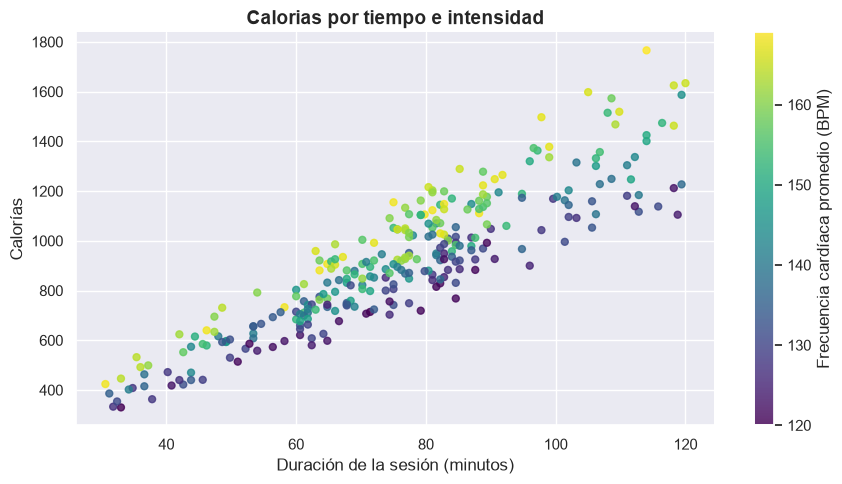

In [219]:
fig, ax = plt.subplots(figsize=(9, 5))
sc = ax.scatter(muestra['Session_Duration (hours)'] * 60, muestra['Calories_Burned'],
                c=muestra['Avg_BPM'], cmap='viridis', s=25, alpha=0.8)
fig.colorbar(sc, ax=ax, label='Frecuencia cardíaca promedio (BPM)')
ax.set_title('Calorias por tiempo e intensidad', fontsize=14, fontweight='bold')
ax.set_xlabel('Duración de la sesión (minutos)')
ax.set_ylabel('Calorías')
sns.despine()
plt.tight_layout()
plt.show()

## Correlaciones ente las variables seleccionadas:

Con esta matriz de correlaciones, confirmo el impacto de las variables analizadas sobre la variable seleccionada Calories_Burned 

En orden de importancia:
* Duracion de la sesion 0.9 - Correlacion positiva fuerte
* Nivel de experiencia 0.68 - Correlacion positiva moderada-fuerte
* Frecuencia de entrenamiento 0.55 - Correlacion positiva moderada
* Frecuencia cardíaca promedio 0.40 - Correlacion positiva moderada
* Edad (Age) y BMI (Indice de masa corporal) tienen un efecto neutro.
* Porcentae de grasa corporal -0.60 - Correlacion negativa moderada 

Si BMI es neutro pero Fat_Porcentaje es negativo se entiende que el porcentaje de masa muscular es el factor que tendría una correlacion positiva, coherente con el hecho de que la masa muscular es tejido activo que genera mayor gasto, no solo por la fisiología del tejido mismo, sino porque está relacionado al nivel de experiencia (observo Fat_Percentaje - Experience_Level corr = -0.67).

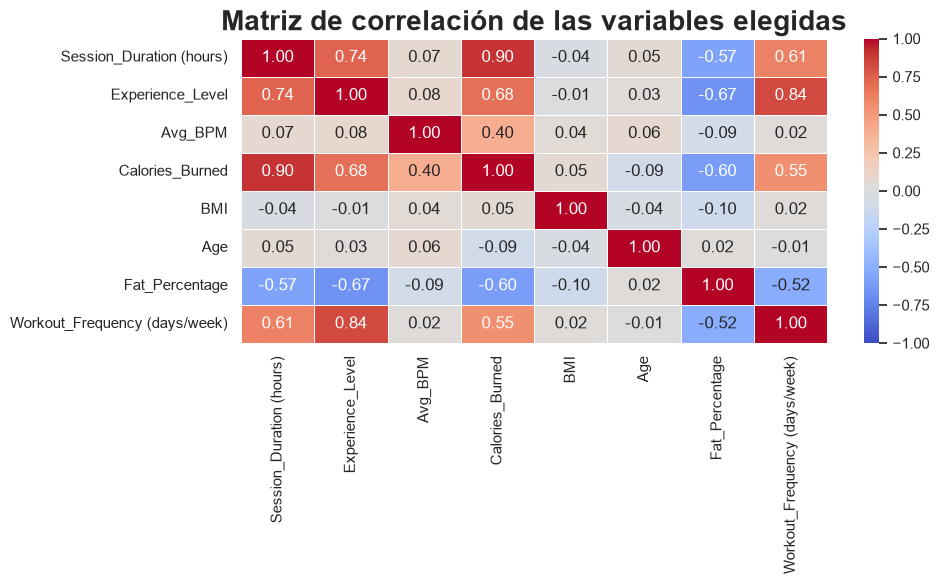

In [227]:
import numpy as np

df_corr = muestra[['Session_Duration (hours)','Experience_Level','Avg_BPM','Calories_Burned', 
'Workout_Type','Gender','BMI','Age','Fat_Percentage','Workout_Frequency (days/week)']]
# Experience_Level ya es numérica y ordinal (1 < 2 < 3)

# 2. Matriz de correlación
corr = df_corr.corr(numeric_only=True)

fig, ax = plt.subplots(figsize=(10, 6))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm',
            vmin=-1, vmax=1, center=0, linewidths=0.5, ax=ax)
ax.set_title('Matriz de correlación de las variables elegidas',
             fontsize=20, fontweight='bold')
plt.tight_layout()
plt.show()

In [221]:
muestra.head(2)

,Age,Gender,Weight (kg),Height (m),Max_BPM,Avg_BPM,Resting_BPM,Session_Duration (hours),Calories_Burned,Workout_Type,Fat_Percentage,Water_Intake (liters),Workout_Frequency (days/week),Experience_Level,BMI,Nivel
741,51,Female,77.3,1.58,171,168,68,0.97,733.0,Cardio,31.1,2.0,2,1,30.96,Principiante
924,18,Male,118.6,1.64,188,134,67,0.94,693.0,Cardio,25.6,2.7,3,1,44.10,Principiante


## Modelo Regresion múltiple:

El intercepto es negativo porque representa una sesión de 0 minutos y 0 BPM, que no existe. No tiene interpretación práctica, solo ubica la recta.

Aplique drop_first=True al hacer el enconding de Workout_Type para dejar a Cardio como referencia, los valores de los demás Workout_Type parten de la base del gasto generado por Cardio. 

### Los coeficientes se interpretan:
* Strength −24,82: con la misma duración y el mismo BPM, una sesión de fuerza quema unas 25 calorías menos que una de cardio.
* Yoga −22,38: unas 22 calorías menos que cardio, en las mismas condiciones.
* HIIT −8,12: prácticamente igual que cardio.
* Minutos: cada minuto extra de sesión suma 11.67 calorías. Este es el factor que mayor influencia tiene según los coeficientes obtenidos.
* Avg_BPM: cada latido por minuto suma 6.34 calorías, entrenar mas intenso son más calorías quemadas.
* Workout_Type HIIT, Strength y Yoga: Todas estan debajo de Cardio por menos de 25 calorías, la diferencia es muy poca, podría decirse que el tipo de entrenamiento no es un factor que influya a igualdad de condiciones de las demas variables.
* Gender Male: Los hombres consumen 88.42 calorías mas por minuto que las mujeres

### Métricas:
* R² = 0,928: el modelo explica el 92,8 % de la variación del gasto calórico.
* RMSE = 73 calorías: en promedio, el modelo se equivoca en ±73 calorías, alrededor del 8 % de la media (905).
* MAE = 57,7 calorías: el error típico, menos sensible a los valores extremos.


In [232]:
import pandas as pd
import numpy as np
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error

# Variables
X = muestra[['Session_Duration (hours)', 'Experience_Level', 'Avg_BPM',
             'Workout_Type','Gender','Age']].copy()
y = muestra['Calories_Burned']

# Duración en minutos (el coeficiente se interpreta mejor)
X['Minutos'] = X['Session_Duration (hours)'] * 60
X = X.drop(columns=['Session_Duration (hours)'])

# Encoding de Workout_Type (drop_first deja a Cardio como la referencia)
X = pd.get_dummies(X, columns=['Workout_Type','Gender'], drop_first=True, dtype=int)
# Cardio queda como categoría de referencia

# Modelo
modelo = LinearRegression()
modelo.fit(X, y)

# Coeficientes
coef = pd.DataFrame({'Variable': X.columns, 'Coeficiente': modelo.coef_.round(2)})
print()
print(f'Intercepto: {modelo.intercept_:.2f}')
display(coef)

# Métricas
y_pred = modelo.predict(X)
print(f'R²:   {r2_score(y, y_pred):.3f}')
print(f'RMSE: {np.sqrt(mean_squared_error(y, y_pred)):.1f} calorías')
print(f'MAE:  {mean_absolute_error(y, y_pred):.1f} calorías')


Intercepto: -798.78


,Variable,Coeficiente
0,Experience_Level,0.73
1,Avg_BPM,6.26
2,Age,-3.53
3,Minutos,11.94
4,Workout_Type_HIIT,-0.39
5,Workout_Type_Strength,-10.52
6,Workout_Type_Yoga,-8.60
7,Gender_Male,85.92


R²:   0.977
RMSE: 41.0 calorías
MAE:  31.1 calorías


## Analisis de residuos:

Se cumplen la linealidad y la homocedasticidad. Persiste una leve curvatura en los extremos (sesiones de gasto muy bajo o muy alto), atribuible a que el gasto depende del producto entre duración e intensidad.

El histograma de distribucion de residuos tiene una forma normal centrada en cero, como es esperable. Las colas en -100 y 100-150 contienen pocos valores, pero el supuesto de normalidad suele ser robusto a pequeñas desviaciones de la normalidad, especialmente cuando el tamaño de la muestra es grande

Mayor influencia: Gender_Male


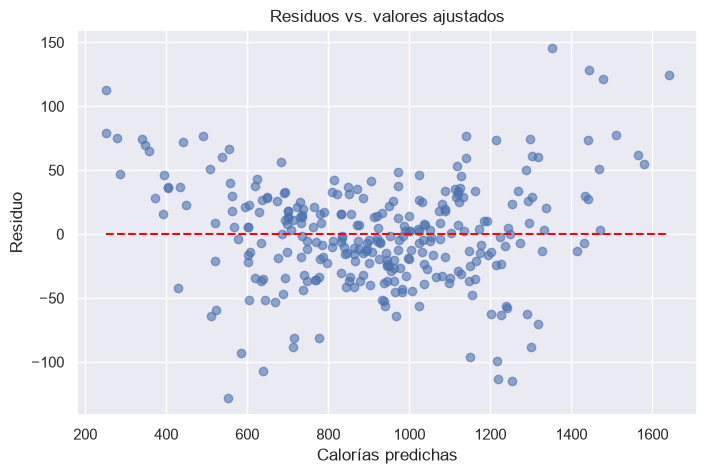

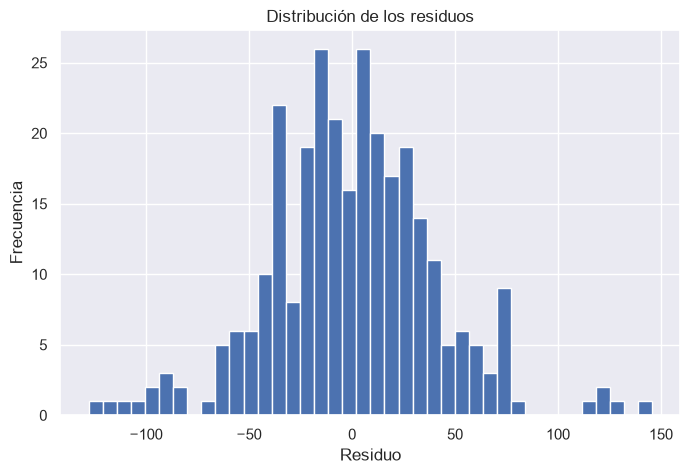

In [235]:
# Valores ajustados y residuos 
y_pred = modelo.predict(X)
residuos = y - y_pred

# Variable con mayor influencia (igual que en el Módulo 10)
print('Mayor influencia:', X.columns[np.argmax(abs(modelo.coef_))])

# Linealidad y homocedasticidad: residuos vs. valores ajustados
plt.figure(figsize=(8, 5))
plt.scatter(y_pred, residuos, alpha=0.6)
plt.plot([y_pred.min(), y_pred.max()], [0, 0], color='red', linestyle='--')
plt.xlabel('Calorías predichas')
plt.ylabel('Residuo')
plt.title('Residuos vs. valores ajustados')
plt.show()

# Normalidad: histograma de los residuos
plt.figure(figsize=(8, 5))
plt.hist(residuos, bins=40, edgecolor='white')
plt.xlabel('Residuo')
plt.ylabel('Frecuencia')
plt.title('Distribución de los residuos')
plt.show()


# Conclusiones:
### ¿Qué hace que un entrenamiento queme más calorías? 
La duración (≈ 12 kcal por minuto) y la intensidad (≈ 6 kcal por cada BPM).

### ¿Qué factores lo explican? 
Duración y frecuencia cardíaca explican, junto con el resto de las variables, el 92,8 % de la variación (R²). El nivel de experiencia influye sobre todo porque los expertos entrenan sesiones más largas.

### ¿Tipo o forma de entrenar? 
La forma: las diferencias entre tipos son menores a 25 kcal, por debajo del error del modelo (73 kcal).

## Recomendación: priorizar la duración y la intensidad de las sesiones antes que elegir un tipo de entrenamiento “que quema más”.